<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_9_Text_Processing_and_Multiclass_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 9 — Text Processing and Multiclass Classification (Pemrosesan Teks dan Klasifikasi Multikelas)

Notebook ini mempelajari cara mengubah teks mentah menjadi fitur numerik untuk digunakan dalam klasifikasi machine learning. Materinya mengikuti pokok bahasan Bab 9 dari *scikit-learn Cookbook, Third Edition*, dengan penjelasan dan implementasi yang disusun secara mandiri.

## Tujuan pembelajaran

Setelah menyelesaikan notebook ini, kamu diharapkan mampu:

1. Menjelaskan alur dasar pemrosesan teks.
2. Mengubah teks menjadi fitur Bag-of-Words dan TF-IDF.
3. Mengekstrak n-gram dan memeriksa tag part-of-speech (POS) sederhana.
4. Membuat dan membandingkan model klasifikasi teks.
5. Membandingkan strategi One-vs-Rest (OvR) dan One-vs-One (OvO).
6. Mengevaluasi model teks menggunakan precision, recall, F1-score, dan confusion matrix.

> **Catatan reproduksibilitas:** contoh akan mencoba menggunakan corpus NLTK `movie_reviews`, `reuters`, dan `brown` jika sudah tersedia. Jika corpus belum terpasang—misalnya saat bekerja tanpa internet—notebook menggunakan dataset demonstrasi lokal yang hasilnya konsisten. Petunjuk untuk mengunduh corpus asli di Google Colab tersedia di bawah.

## Persiapan lingkungan

Pustaka utama yang digunakan adalah NLTK, pandas, Matplotlib, dan scikit-learn. Di Google Colab, pasang pustaka jika belum tersedia:

```python
%pip install nltk scikit-learn pandas matplotlib seaborn
```

Untuk menjalankan contoh menggunakan dataset NLTK asli, jalankan kode opsional berikut pada sebuah sel, lalu jalankan ulang notebook dari awal:

```python
import nltk
nltk.download('movie_reviews')
nltk.download('reuters')
nltk.download('brown')
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger_eng')
```

Notebook tidak mengunduh data secara otomatis. Dengan begitu, notebook tetap dapat digunakan di lingkungan yang tidak memiliki akses internet.

In [ ]:
import re
import random
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 2024
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print(f"scikit-learn: ready | NLTK: {nltk.__version__}")

scikit-learn: ready | NLTK: 3.9.1


### Fungsi bantuan untuk dataset mandiri

Fungsi bantuan di bawah terlebih dahulu mencoba membaca corpus NLTK yang digunakan pada contoh buku. Jika corpus belum terpasang, fungsi akan mengembalikan contoh buatan dengan istilah yang berbeda untuk tiap kelas. Dataset pengganti ini digunakan untuk mempelajari alur kerja, bukan sebagai pengganti evaluasi ilmiah menggunakan corpus nyata.

In [ ]:
def make_sentiment_demo(n_per_class=180):
    """Create a deterministic small text corpus when NLTK movie_reviews is absent."""
    positive_adj = ["excellent", "moving", "engaging", "wonderful", "clever", "memorable", "impressive", "delightful"]
    positive_nouns = ["story", "acting", "direction", "soundtrack", "characters", "ending", "dialogue", "cinematography"]
    positive_verbs = ["enjoyed", "admired", "recommended", "appreciated", "remembered", "loved"]
    negative_adj = ["dull", "confusing", "weak", "boring", "predictable", "awful", "unconvincing", "disappointing"]
    negative_nouns = ["story", "acting", "direction", "soundtrack", "characters", "ending", "dialogue", "cinematography"]
    negative_verbs = ["disliked", "regretted", "criticized", "avoided", "forgot", "rejected"]
    positive_templates = [
        "The {adj} film has {noun} and I {verb} it.",
        "A {adj} movie with {noun}; the performance feels fresh.",
        "I found the {noun} {adj}, so I gladly {verb} this film.",
        "This movie is {adj}; the {noun} works very well."
    ]
    negative_templates = [
        "The {adj} film has {noun} and I {verb} it.",
        "A {adj} movie with {noun}; the performance feels weak.",
        "I found the {noun} {adj}, so I strongly {verb} this film.",
        "This movie is {adj}; the {noun} does not work well."
    ]
    texts, labels = [], []
    for i in range(n_per_class):
        texts.append(positive_templates[i % len(positive_templates)].format(
            adj=positive_adj[i % len(positive_adj)],
            noun=positive_nouns[(i * 3) % len(positive_nouns)],
            verb=positive_verbs[(i * 5) % len(positive_verbs)]
        ) + f" Example detail {i % 13}.")
        labels.append("pos")
        texts.append(negative_templates[i % len(negative_templates)].format(
            adj=negative_adj[i % len(negative_adj)],
            noun=negative_nouns[(i * 3) % len(negative_nouns)],
            verb=negative_verbs[(i * 5) % len(negative_verbs)]
        ) + f" Example detail {i % 13}.")
        labels.append("neg")
    return texts, labels


def make_topic_demo(n_per_class=60):
    """Create multi-topic demo documents for offline text-classification examples."""
    topic_terms = {
        "sports": ["coach", "team", "tournament", "player", "stadium", "score", "training", "league", "match", "referee"],
        "technology": ["software", "computer", "processor", "network", "database", "algorithm", "device", "security", "cloud", "code"],
        "finance": ["market", "shares", "investment", "bank", "profit", "currency", "trading", "revenue", "loan", "capital"],
        "health": ["patient", "doctor", "clinic", "treatment", "symptom", "medicine", "recovery", "healthcare", "diagnosis", "therapy"],
        "travel": ["airport", "hotel", "journey", "tourist", "luggage", "destination", "museum", "flight", "guide", "ticket"],
        "cooking": ["recipe", "kitchen", "ingredient", "oven", "sauce", "vegetable", "flavor", "baking", "meal", "spice"]
    }
    templates = [
        "The report discusses {a} and {b} in detail.",
        "Experts described how {a} can affect {b}.",
        "The latest update focuses on {a}, while {b} remains important.",
        "Readers learned about {a}, {b}, and practical planning.",
        "The discussion connects {a} with {b} and {c}."
    ]
    texts, labels = [], []
    for label, terms in topic_terms.items():
        for i in range(n_per_class):
            a = terms[i % len(terms)]
            b = terms[(i * 3 + 2) % len(terms)]
            c = terms[(i * 7 + 4) % len(terms)]
            text = templates[i % len(templates)].format(a=a, b=b, c=c)
            text += f" Additional details and example number {i % 17} are included."
            texts.append(text)
            labels.append(label)
    return texts, labels


def load_movie_reviews_data():
    try:
        from nltk.corpus import movie_reviews
        fileids = movie_reviews.fileids()
        if fileids:
            texts = [movie_reviews.raw(fileid) for fileid in fileids]
            labels = [movie_reviews.categories(fileid)[0] for fileid in fileids]
            return texts, labels, "NLTK movie_reviews corpus"
    except LookupError:
        pass
    texts, labels = make_sentiment_demo()
    return texts, labels, "self-contained sentiment demo (fallback)"


def load_reuters_data():
    try:
        from nltk.corpus import reuters
        fileids = reuters.fileids()
        if fileids:
            texts, labels = [], []
            for fileid in fileids:
                categories = reuters.categories(fileid)
                if categories:
                    texts.append(reuters.raw(fileid))
                    labels.append(categories[0])
            if texts:
                return texts, labels, "NLTK Reuters corpus"
    except LookupError:
        pass
    texts, labels = make_topic_demo()
    return texts, labels, "self-contained multi-topic demo (fallback)"


def load_brown_data():
    try:
        from nltk.corpus import brown
        fileids = brown.fileids()
        if fileids:
            texts, labels = [], []
            for fileid in fileids:
                categories = brown.categories(fileid)
                if categories:
                    texts.append(" ".join(brown.words(fileid)))
                    labels.append(categories[0])
            if texts:
                return texts, labels, "NLTK Brown corpus"
    except LookupError:
        pass
    texts, labels = make_topic_demo()
    return texts, labels, "self-contained multi-topic demo (fallback)"


def simple_pos_tag(tokens):
    """Very rough POS fallback used only if NLTK's trained tagger is unavailable."""
    tagged = []
    determiners = {"a", "an", "the", "this", "that", "these", "those"}
    pronouns = {"i", "you", "he", "she", "it", "we", "they", "them", "us"}
    conjunctions = {"and", "or", "but", "because", "while"}
    for token in tokens:
        low = token.lower()
        if re.fullmatch(r"[^\w\s]", token): tag = "."
        elif low in determiners: tag = "DT"
        elif low in pronouns: tag = "PRP"
        elif low in conjunctions: tag = "CC"
        elif low.endswith("ly"): tag = "RB"
        elif low.endswith(("ing", "ed")): tag = "VB"
        elif low.endswith(("ous", "ful", "ive", "able", "al")): tag = "JJ"
        else: tag = "NN"
        tagged.append((token, tag))
    return tagged

print("Fungsi bantuan pemuatan dataset siap.")

Fungsi bantuan pemuatan dataset siap.


## 9.1 Pengenalan pemrosesan teks

Model klasifikasi teks membutuhkan masukan numerik. Alur kerja yang umum adalah:

\[
	ext{Teks mentah}
ightarrow 	ext{token}
ightarrow 	ext{fitur numerik}
ightarrow 	ext{classifier}
ightarrow 	ext{prediksi}
\]

Tahap prapemrosesan dapat mencakup mengubah huruf menjadi huruf kecil, tokenisasi, penanganan tanda baca, dan penyaringan stopword. Langkah pembersihan harus disesuaikan dengan tugas. Dalam analisis sentimen, misalnya, kata negasi seperti *not* bisa membawa informasi penting.

### Memuat corpus ulasan film dan membagi data

Contoh pada buku menggunakan corpus `movie_reviews` dari NLTK, yang berisi ulasan positif dan negatif. Sel berikut memuat corpus tersebut jika tersedia; jika tidak, notebook menggunakan data demonstrasi lokal.

In [ ]:
texts_sentiment, labels_sentiment, sentiment_source = load_movie_reviews_data()
print(f"Sumber data: {sentiment_source}")
print(f"Jumlah dokumen: {len(texts_sentiment)}")
print(f"Distribusi kelas: {dict(Counter(labels_sentiment))}")
print("\nContoh ulasan:")
print(texts_sentiment[0][:350].replace("\n", " "))

Sumber data: self-contained sentiment demo (fallback)
Jumlah dokumen: 360
Distribusi kelas: {'pos': 180, 'neg': 180}

Contoh ulasan:
The excellent film has story and I enjoyed it. Example detail 0.


In [ ]:
# Gunakan subset yang konsisten agar contoh vektorisasi awal berjalan cepat.
subset_size = min(500, len(texts_sentiment))
if len(texts_sentiment) > subset_size:
    texts_subset, _, labels_subset, _ = train_test_split(
        texts_sentiment, labels_sentiment,
        train_size=subset_size,
        stratify=labels_sentiment,
        random_state=RANDOM_STATE
    )
else:
    texts_subset, labels_subset = list(texts_sentiment), list(labels_sentiment)
X_train, X_test, y_train, y_test = train_test_split(
    texts_subset, labels_subset,
    test_size=0.30,
    stratify=labels_subset,
    random_state=RANDOM_STATE
)
print(f"Subset: {len(texts_subset)} | latih: {len(X_train)} | uji: {len(X_test)}")
print(f"Label data latih: {dict(Counter(y_train))}")
print(f"Label data uji:     {dict(Counter(y_test))}")

Subset: 360 | latih: 252 | uji: 108
Label data latih: {'pos': 126, 'neg': 126}
Label data uji:     {'pos': 54, 'neg': 54}


### Bag of Words dengan `CountVectorizer`

`CountVectorizer` membangun kosakata dari dokumen pelatihan dan merepresentasikan setiap dokumen sebagai jumlah kemunculan kata. Matriks dokumen-istilah yang dihasilkan biasanya bersifat *sparse* karena satu dokumen hanya menggunakan sebagian kecil dari seluruh kosakata.

Gunakan `fit_transform` hanya pada teks latih, lalu gunakan `transform` pada teks uji. Jika vectorizer dilatih menggunakan seluruh dataset, informasi dari data uji akan bocor ke alur pelatihan.

In [ ]:
bow_vectorizer = CountVectorizer(stop_words="english", min_df=1, max_features=12000)
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

possible_entries = X_train_bow.shape[0] * X_train_bow.shape[1]
sparsity = 1 - X_train_bow.nnz / possible_entries
print(f"Ukuran matriks latih: {X_train_bow.shape}")
print(f"Ukuran matriks uji:  {X_test_bow.shape}")
print(f"Ukuran kosakata:    {len(bow_vectorizer.vocabulary_):,}")
print(f"Sparsity matriks:    {sparsity:.2%}")
print("12 istilah pertama dalam kosakata:", bow_vectorizer.get_feature_names_out()[:12].tolist())

Ukuran matriks latih: (252, 44)
Ukuran matriks uji:  (108, 44)
Ukuran kosakata:    44
Sparsity matriks:    86.11%
12 istilah pertama dalam kosakata: ['10', '11', '12', 'acting', 'awful', 'boring', 'characters', 'cinematography', 'clever', 'confusing', 'criticized', 'delightful']


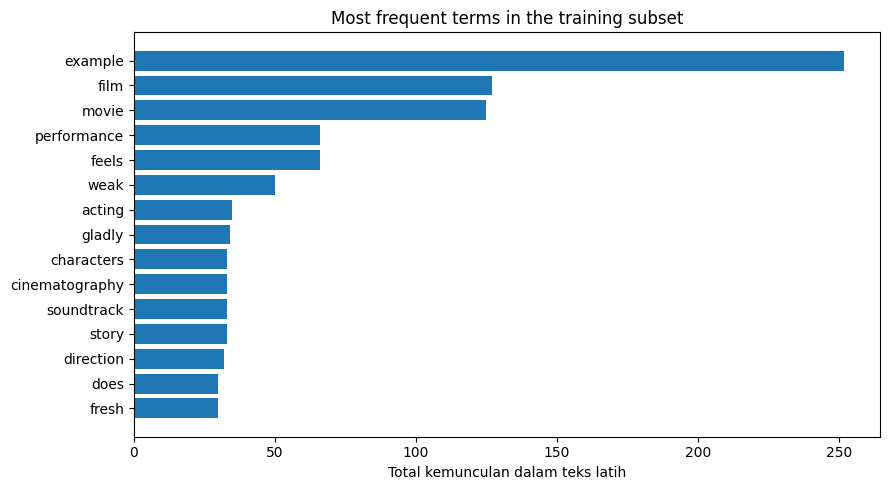

In [ ]:
feature_names = bow_vectorizer.get_feature_names_out()
word_counts = np.asarray(X_train_bow.sum(axis=0)).ravel()
top_indices = np.argsort(word_counts)[-15:]

plt.figure(figsize=(9, 5))
plt.barh(feature_names[top_indices], word_counts[top_indices])
plt.xlabel("Total kemunculan dalam teks latih")
plt.title("Most frequent terms in the training subset")
plt.tight_layout()
plt.show()

**Interpretasi:** grafik frekuensi membantu memperlihatkan kosakata dalam corpus, tetapi frekuensi saja tidak menunjukkan apakah suatu kata berguna untuk membedakan kelas. Kata yang sangat umum bisa muncul pada beberapa kelas. Karena itu, bagian berikut membandingkan jumlah mentah kata dengan pembobotan TF-IDF.

## 9.2 Teknik vektorisasi teks

Dua representasi teks yang umum adalah:

- **Bag of Words (BoW):** mencatat seberapa sering setiap istilah muncul di sebuah dokumen.
- **TF-IDF:** menggabungkan frekuensi istilah dan frekuensi dokumen terbalik, sehingga bobot istilah yang muncul di banyak dokumen berkurang dan istilah yang relatif khas mendapat bobot lebih besar.

Perbandingan di bawah memakai corpus Reuters jika tersedia, atau corpus beberapa topik yang dibuat secara lokal. Tujuannya adalah memeriksa representasi fitur, bukan menyatakan satu metode selalu lebih baik daripada metode lainnya.

In [ ]:
texts_reuters, labels_reuters, reuters_source = load_reuters_data()
print(f"Sumber data: {reuters_source}")
print(f"Jumlah dokumen: {len(texts_reuters)} | label berbeda: {len(set(labels_reuters))}")
print("Label yang paling sering muncul:", Counter(labels_reuters).most_common(8))

# Batasi demonstrasi vektorisasi agar penggunaan memori tetap wajar jika corpus Reuters lengkap tersedia.
if len(texts_reuters) > 3000:
    texts_r, _, labels_r, _ = train_test_split(
        texts_reuters, labels_reuters, train_size=3000,
        random_state=RANDOM_STATE
    )
else:
    texts_r, labels_r = texts_reuters, labels_reuters
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    texts_r, labels_r, test_size=0.30, random_state=RANDOM_STATE
)
print(f"Subset yang digunakan: {len(texts_r)} | pelatihan: {len(X_train_r)} | uji: {len(X_test_r)}")

Sumber data: self-contained multi-topic demo (fallback)
Jumlah dokumen: 360 | label berbeda: 6
Label yang paling sering muncul: [('sports', 60), ('technology', 60), ('finance', 60), ('health', 60), ('travel', 60), ('cooking', 60)]
Subset yang digunakan: 360 | pelatihan: 252 | uji: 108


In [ ]:
bow_r = CountVectorizer(stop_words="english", min_df=2, max_features=5000)
tfidf_r = TfidfVectorizer(stop_words="english", min_df=2, max_features=5000)

X_train_bow_r = bow_r.fit_transform(X_train_r)
X_test_bow_r = bow_r.transform(X_test_r)
X_train_tfidf_r = tfidf_r.fit_transform(X_train_r)
X_test_tfidf_r = tfidf_r.transform(X_test_r)

for name, matrix in [("BoW", X_train_bow_r), ("TF-IDF", X_train_tfidf_r)]:
    total = matrix.shape[0] * matrix.shape[1]
    print(f"{name}: bentuk={matrix.shape}, elemen bukan nol={matrix.nnz:,}, sparsity={1-matrix.nnz/total:.2%}")

BoW: bentuk=(252, 88), elemen bukan nol=2,659, sparsity=88.01%
TF-IDF: bentuk=(252, 88), elemen bukan nol=2,659, sparsity=88.01%


In [ ]:
# Bandingkan kedua representasi untuk istilah pada dokumen contoh yang sama.
sample_idx = 0
bow_row = X_train_bow_r[sample_idx].toarray().ravel()
tfidf_row = X_train_tfidf_r[sample_idx].toarray().ravel()
nonzero = np.flatnonzero(bow_row)[:10]
bow_names = bow_r.get_feature_names_out()
comparison = pd.DataFrame({
    "term": bow_names[nonzero],
    "BoW count": bow_row[nonzero].astype(int),
    "TF-IDF weight": tfidf_row[nonzero].round(4)
})
comparison

,term,BoW count,TF-IDF weight
0,additional,1,0.1198
1,details,1,0.1198
2,example,1,0.1198
3,focuses,1,0.3049
4,healthcare,1,0.4667
5,important,1,0.3049
6,included,1,0.1198
7,latest,1,0.3049
8,number,1,0.1198
9,remains,1,0.3049


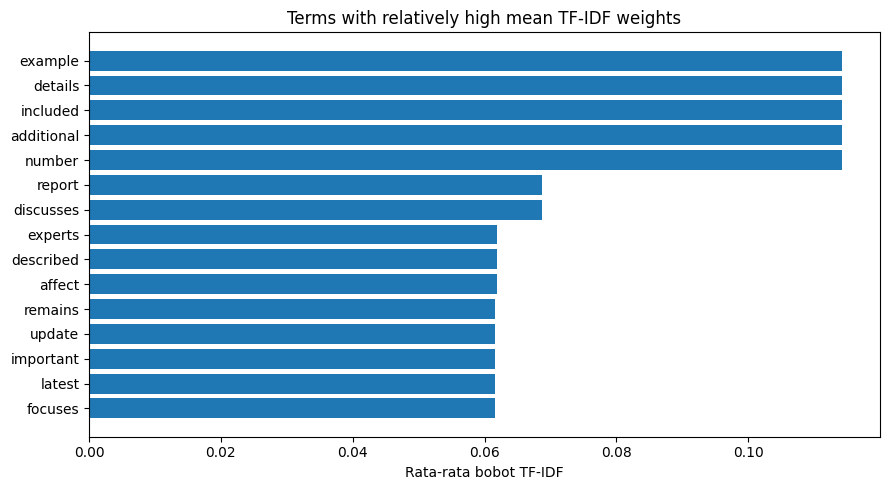

In [ ]:
# Visualisasikan istilah dengan bobot rata-rata TF-IDF tinggi pada data latih.
mean_weights = np.asarray(X_train_tfidf_r.mean(axis=0)).ravel()
tfidf_names = tfidf_r.get_feature_names_out()
top = np.argsort(mean_weights)[-15:]
plt.figure(figsize=(9, 5))
plt.barh(tfidf_names[top], mean_weights[top])
plt.xlabel("Rata-rata bobot TF-IDF")
plt.title("Terms with relatively high mean TF-IDF weights")
plt.tight_layout()
plt.show()

**Perbedaan penting:** bobot TF-IDF ditentukan oleh frekuensi istilah dan frekuensi dokumen di dalam corpus. Nilai TF-IDF yang tinggi tidak otomatis berarti sebuah kata penting secara semantik; penafsirannya tetap bergantung pada corpus dan tujuan tugas.

## 9.3 Ekstraksi fitur dari teks

N-gram merupakan rangkaian token yang berurutan. *Unigram* terdiri dari satu token, *bigram* berisi dua token yang berdekatan, dan *trigram* berisi tiga token. N-gram dapat menangkap frasa seperti “not good” yang mungkin terlewat jika hanya menggunakan representasi satu kata.

In [ ]:
texts_brown, labels_brown, brown_source = load_brown_data()
print(f"Sumber data: {brown_source}")
print(f"Jumlah dokumen: {len(texts_brown)} | genres/classes: {len(set(labels_brown))}")
print("Most common categories:", Counter(labels_brown).most_common(8))

# Gunakan sampel kecil untuk menunjukkan n-gram dan penandaan token.
sample_texts = texts_brown[:8]
for i, sample in enumerate(sample_texts[:3], start=1):
    print(f"\nSampel {i}: {sample[:240]}")

Sumber data: self-contained multi-topic demo (fallback)
Jumlah dokumen: 360 | genres/classes: 6
Most common categories: [('sports', 60), ('technology', 60), ('finance', 60), ('health', 60), ('travel', 60), ('cooking', 60)]

Sampel 1: The report discusses coach and tournament in detail. Additional details and example number 0 are included.

Sampel 2: Experts described how team can affect score. Additional details and example number 1 are included.

Sampel 3: The latest update focuses on tournament, while match remains important. Additional details and example number 2 are included.


In [ ]:
example_texts = [
    "the model learns from short text examples",
    "the text model learns useful word patterns",
    "word patterns can improve text classification"
]
ngram_vectorizer = CountVectorizer(ngram_range=(1, 2), stop_words="english")
X_ngrams = ngram_vectorizer.fit_transform(example_texts)
ngram_features = ngram_vectorizer.get_feature_names_out()
print(f"Ukuran matriks n-gram contoh: {X_ngrams.shape}")
print("Unigram:", [f for f in ngram_features if " " not in f])
print("Bigram:", [f for f in ngram_features if " " in f])

Ukuran matriks n-gram contoh: (3, 21)
Unigram: ['classification', 'examples', 'improve', 'learns', 'model', 'patterns', 'short', 'text', 'useful', 'word']
Bigram: ['improve text', 'learns short', 'learns useful', 'model learns', 'patterns improve', 'short text', 'text classification', 'text examples', 'text model', 'useful word', 'word patterns']


### Penandaan part-of-speech (POS)

Tag POS menandai fungsi gramatikal kata, misalnya kata benda, kata kerja, kata sifat, atau kata penentu. Tagger terlatih dari NLTK memberikan penandaan linguistik yang lebih baik jika sumber datanya tersedia. Tagger pengganti di bawah sengaja dibuat sederhana agar demonstrasi tetap bisa dijalankan tanpa internet.

In [ ]:
def tokenize_text(text):
    """Use NLTK tokenization when available; otherwise use a simple regex tokenizer."""
    try:
        return nltk.word_tokenize(text)
    except LookupError:
        return re.findall(r"[A-Za-z]+|[^\w\s]", text)


def tag_text(text):
    tokens = tokenize_text(text)
    try:
        return nltk.pos_tag(tokens), "NLTK trained tagger"
    except LookupError:
        return simple_pos_tag(tokens), "simple fallback tags (illustrative only)"

for text in sample_texts[:3]:
    tags, method = tag_text(text)
    print(f"\nMetode: {method}\n{text}\n{tags}")


Metode: simple fallback tags (illustrative only)
The report discusses coach and tournament in detail. Additional details and example number 0 are included.
[('The', 'DT'), ('report', 'NN'), ('discusses', 'NN'), ('coach', 'NN'), ('and', 'CC'), ('tournament', 'NN'), ('in', 'NN'), ('detail', 'NN'), ('.', '.'), ('Additional', 'JJ'), ('details', 'NN'), ('and', 'CC'), ('example', 'NN'), ('number', 'NN'), ('are', 'NN'), ('included', 'VB'), ('.', '.')]

Metode: simple fallback tags (illustrative only)
Experts described how team can affect score. Additional details and example number 1 are included.
[('Experts', 'NN'), ('described', 'VB'), ('how', 'NN'), ('team', 'NN'), ('can', 'NN'), ('affect', 'NN'), ('score', 'NN'), ('.', '.'), ('Additional', 'JJ'), ('details', 'NN'), ('and', 'CC'), ('example', 'NN'), ('number', 'NN'), ('are', 'NN'), ('included', 'VB'), ('.', '.')]

Metode: simple fallback tags (illustrative only)
The latest update focuses on tournament, while match remains important. Addit

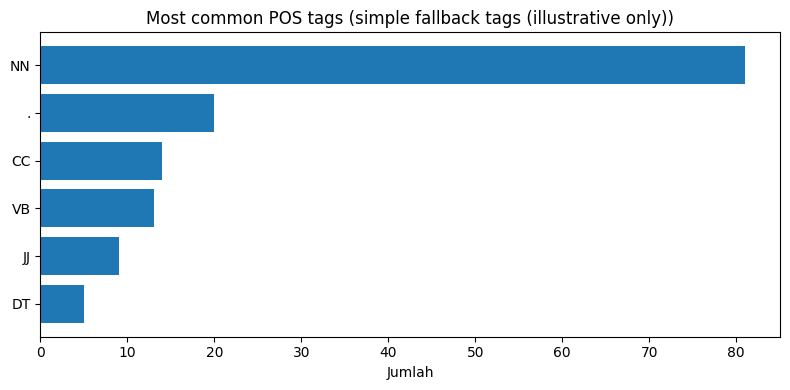

Jumlah tag POS: {'NN': 81, '.': 20, 'CC': 14, 'VB': 13, 'JJ': 9, 'DT': 5}


In [ ]:
# Rangkum tag POS dari sejumlah kecil dokumen.
pos_tags = []
method_used = None
for text in sample_texts[:30]:
    tagged, method_used = tag_text(text)
    pos_tags.extend(tag for _, tag in tagged)

pos_counts = Counter(pos_tags)
top_pos = pos_counts.most_common(10)
if top_pos:
    tag_names, tag_counts = zip(*top_pos)
    plt.figure(figsize=(8, 4))
    plt.barh(list(tag_names)[::-1], list(tag_counts)[::-1])
    plt.xlabel("Jumlah")
    plt.title(f"Most common POS tags ({method_used})")
    plt.tight_layout()
    plt.show()
print("Jumlah tag POS:", dict(top_pos))

## 9.4 Menerapkan model klasifikasi teks

Fitur teks bisa digunakan oleh berbagai classifier. Bagian ini membandingkan tiga pilihan umum:

- **Multinomial Naive Bayes:** model probabilistik sebagai baseline yang cocok untuk fitur teks nonnegatif, seperti hitungan kata atau TF-IDF.
- **Support Vector Machine (SVM):** mencari batas pemisah; kernel linear sering praktis untuk fitur teks yang sparse dan berdimensi tinggi.
- **Logistic Regression:** mempelajari probabilitas kelas atau skor keputusan dari vektor fitur.

Agar eksperimen multikelas tetap ringan dan pembagian stratifikasi dapat dilakukan, kode menggunakan kategori paling sering muncul dalam corpus Brown atau corpus demonstrasi yang dipilih.

In [ ]:
# Gunakan hingga enam kategori yang memiliki cukup contoh untuk pembagian stratifikasi yang konsisten.
label_counts = Counter(labels_brown)
eligible_labels = [label for label, count in label_counts.most_common() if count >= 8][:6]
selected = [(text, label) for text, label in zip(texts_brown, labels_brown) if label in eligible_labels]
texts_class = [text for text, _ in selected]
labels_class = [label for _, label in selected]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    texts_class, labels_class,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=labels_class
)
print("Label terpilih:", eligible_labels)
print(f"Samples: {len(texts_class)} | latih: {len(X_train_c)} | uji: {len(X_test_c)}")
print("Jumlah sampel per label:", dict(Counter(labels_class)))

Label terpilih: ['sports', 'technology', 'finance', 'health', 'travel', 'cooking']
Samples: 360 | latih: 252 | uji: 108
Jumlah sampel per label: {'sports': 60, 'technology': 60, 'finance': 60, 'health': 60, 'travel': 60, 'cooking': 60}


In [ ]:
text_vectorizer_c = TfidfVectorizer(stop_words="english", max_features=12000, min_df=1)
X_train_c_tfidf = text_vectorizer_c.fit_transform(X_train_c)
X_test_c_tfidf = text_vectorizer_c.transform(X_test_c)

classifiers = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Linear-kernel SVM": SVC(kernel="linear", random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(max_iter=1500, random_state=RANDOM_STATE)
}

model_results = []
trained_models = {}
for name, model in classifiers.items():
    model.fit(X_train_c_tfidf, y_train_c)
    pred = model.predict(X_test_c_tfidf)
    trained_models[name] = model
    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_c, pred),
        "Weighted precision": precision_score(y_test_c, pred, average="weighted", zero_division=0),
        "Weighted recall": recall_score(y_test_c, pred, average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_test_c, pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(model_results).sort_values("Weighted F1", ascending=False)
results_df

,Model,Accuracy,Weighted precision,Weighted recall,Weighted F1
0,Multinomial Naive Bayes,1.0,1.0,1.0,1.0
1,Linear-kernel SVM,1.0,1.0,1.0,1.0
2,Logistic Regression,1.0,1.0,1.0,1.0


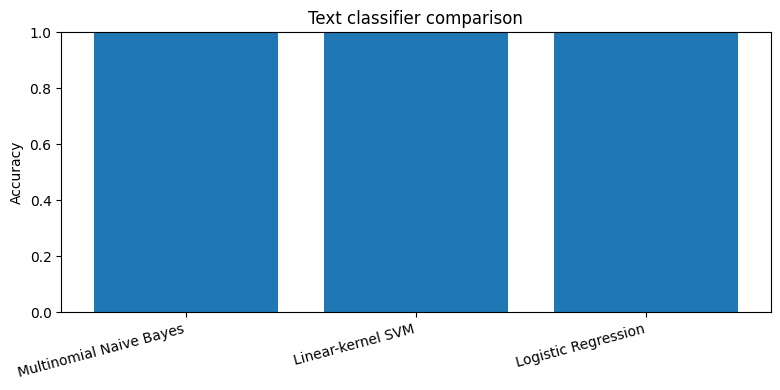

Akurasi tertinggi pada eksperimen ini: Multinomial Naive Bayes
              precision    recall  f1-score   support

     cooking       1.00      1.00      1.00        18
     finance       1.00      1.00      1.00        18
      health       1.00      1.00      1.00        18
      sports       1.00      1.00      1.00        18
  technology       1.00      1.00      1.00        18
      travel       1.00      1.00      1.00        18

    accuracy                           1.00       108
   macro avg       1.00      1.00      1.00       108
weighted avg       1.00      1.00      1.00       108



In [ ]:
plt.figure(figsize=(8, 4))
plt.bar(results_df["Model"], results_df["Accuracy"])
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Text classifier comparison")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test_c_tfidf)
print(f"Akurasi tertinggi pada eksperimen ini: {best_model_name}")
print(classification_report(y_test_c, best_predictions, zero_division=0))

**Interpretasi:** satu skor saja tidak membuktikan bahwa satu algoritma selalu lebih unggul. Hasil dipengaruhi ukuran corpus, keseimbangan kelas, kosakata, prapemrosesan, dan pengaturan model. Agar perbandingan adil, semua model di atas menggunakan pembagian data latih/uji dan fitur hasil vektorisasi yang sama.

## 9.5 Strategi klasifikasi multikelas

Classifier biner dapat diperluas untuk menangani banyak kelas dengan beberapa cara:

- **One-vs-Rest (OvR):** melatih satu classifier biner untuk setiap kelas, yaitu kelas tersebut dibandingkan dengan semua kelas lainnya.
- **One-vs-One (OvO):** melatih classifier untuk setiap pasangan kelas. Jika ada \(K\) kelas, diperlukan \(K(K-1)/2\) classifier biner.

Implementasi berikut membandingkan kedua strategi menggunakan Logistic Regression dan fitur TF-IDF yang sama.

In [ ]:
# Gunakan kembali pembagian data latih/uji dan fitur TF-IDF dari Bagian 9.4.
ovr = OneVsRestClassifier(LogisticRegression(max_iter=1500, random_state=RANDOM_STATE))
ovo = OneVsOneClassifier(LogisticRegression(max_iter=1500, random_state=RANDOM_STATE))

ovr.fit(X_train_c_tfidf, y_train_c)
ovo.fit(X_train_c_tfidf, y_train_c)
pred_ovr = ovr.predict(X_test_c_tfidf)
pred_ovo = ovo.predict(X_test_c_tfidf)

strategy_results = pd.DataFrame([
    {"Strategy": "One-vs-Rest", "Accuracy": accuracy_score(y_test_c, pred_ovr),
     "Weighted F1": f1_score(y_test_c, pred_ovr, average="weighted", zero_division=0),
     "Binary estimators": len(ovr.estimators_)},
    {"Strategy": "One-vs-One", "Accuracy": accuracy_score(y_test_c, pred_ovo),
     "Weighted F1": f1_score(y_test_c, pred_ovo, average="weighted", zero_division=0),
     "Binary estimators": len(ovo.estimators_)}
])
strategy_results

,Strategy,Accuracy,Weighted F1,Binary estimators
0,One-vs-Rest,1.0,1.0,6
1,One-vs-One,1.0,1.0,15


In [ ]:
print("Laporan One-vs-Rest:")
print(classification_report(y_test_c, pred_ovr, zero_division=0))
print("Laporan One-vs-One:")
print(classification_report(y_test_c, pred_ovo, zero_division=0))

Laporan One-vs-Rest:
              precision    recall  f1-score   support

     cooking       1.00      1.00      1.00        18
     finance       1.00      1.00      1.00        18
      health       1.00      1.00      1.00        18
      sports       1.00      1.00      1.00        18
  technology       1.00      1.00      1.00        18
      travel       1.00      1.00      1.00        18

    accuracy                           1.00       108
   macro avg       1.00      1.00      1.00       108
weighted avg       1.00      1.00      1.00       108

Laporan One-vs-One:
              precision    recall  f1-score   support

     cooking       1.00      1.00      1.00        18
     finance       1.00      1.00      1.00        18
      health       1.00      1.00      1.00        18
      sports       1.00      1.00      1.00        18
  technology       1.00      1.00      1.00        18
      travel       1.00      1.00      1.00        18

    accuracy                        

## 9.6 Mengevaluasi model teks

Metrik yang berguna untuk klasifikasi antara lain:

- **Precision:** dari semua contoh yang diprediksi sebagai kelas tertentu, berapa banyak yang benar?
- **Recall:** dari seluruh contoh sebenarnya pada kelas tersebut, berapa banyak yang berhasil ditemukan model?
- **F1-score:** rata-rata harmonik dari precision dan recall.
- **Confusion matrix:** memperlihatkan sebaran prediksi benar dan salah untuk setiap kelas.

Akurasi berguna, tetapi dapat menutupi kinerja yang buruk pada kelas minoritas. Selalu perhatikan distribusi kelas dan konsekuensi dari tiap jenis kesalahan.

In [ ]:
# Evaluasi sentimen pada semua dokumen yang tersedia (corpus buku jika terpasang, jika tidak gunakan demonstrasi pengganti).
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    texts_sentiment, labels_sentiment,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=labels_sentiment
)
vectorizer_e = TfidfVectorizer(stop_words="english", max_features=15000, min_df=1)
X_train_e_tfidf = vectorizer_e.fit_transform(X_train_e)
X_test_e_tfidf = vectorizer_e.transform(X_test_e)

sentiment_model = LogisticRegression(max_iter=1500, random_state=RANDOM_STATE)
sentiment_model.fit(X_train_e_tfidf, y_train_e)
y_pred_e = sentiment_model.predict(X_test_e_tfidf)

print(f"Sumber data: {sentiment_source}")
print(f"Matriks latih: {X_train_e_tfidf.shape} | Test matrix: {X_test_e_tfidf.shape}")
print(f"Akurasi:  {accuracy_score(y_test_e, y_pred_e):.3f}")
print(f"Precision: {precision_score(y_test_e, y_pred_e, average='weighted', zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test_e, y_pred_e, average='weighted', zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test_e, y_pred_e, average='weighted', zero_division=0):.3f}")

Sumber data: self-contained sentiment demo (fallback)
Matriks latih: (252, 44) | Test matrix: (108, 44)
Akurasi:  1.000
Precision: 1.000
Recall:    1.000
F1-score:  1.000


In [ ]:
report = classification_report(y_test_e, y_pred_e, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).transpose()
report_df.round(3)

,precision,recall,f1-score,support
neg,1.0,1.0,1.0,54.0
pos,1.0,1.0,1.0,54.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,108.0
weighted avg,1.0,1.0,1.0,108.0


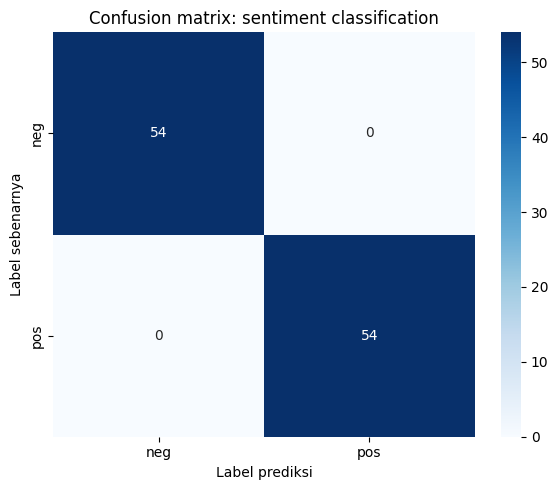

Urutan label: ['neg', 'pos']


In [ ]:
class_order = sorted(set(y_test_e) | set(y_pred_e))
cm = confusion_matrix(y_test_e, y_pred_e, labels=class_order)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_order, yticklabels=class_order)
plt.xlabel("Label prediksi")
plt.ylabel("Label sebenarnya")
plt.title("Confusion matrix: sentiment classification")
plt.tight_layout()
plt.show()
print("Urutan label:", class_order)

### Latihan evaluasi singkat

Perhatikan metrik dan confusion matrix yang baru saja dihasilkan.

1. Apakah akurasi sudah cukup untuk dataset ini? Jelaskan dengan melihat distribusi kelas.
2. Kelas mana yang memiliki recall lebih rendah, dan apa artinya dalam praktik?
3. Jika melewatkan ulasan positif lebih merugikan dibandingkan salah menandai ulasan negatif, metrik apa yang akan kamu prioritaskan? Mengapa?
4. Bagaimana mengurangi risiko kebocoran data dalam proyek klasifikasi teks yang lebih besar?

## Ringkasan bab

Bab ini mengikuti alur lengkap klasifikasi teks:

\[
	ext{Teks}
ightarrow 	ext{prapemrosesan}
ightarrow 	ext{BoW / TF-IDF / n-gram}
ightarrow 	ext{classifier}
ightarrow 	ext{evaluasi}
\]

| Teknik | Tujuan utama | Hal yang perlu diperhatikan |
|---|---|---|
| `CountVectorizer` | Menghitung istilah dalam dokumen | Istilah umum dapat mendominasi nilai fitur |
| `TfidfVectorizer` | Memberi bobot istilah berdasarkan frekuensi dan kelangkaan | Fit hanya pada teks latih untuk mencegah kebocoran data |
| N-gram | Merepresentasikan rangkaian token pendek | N-gram yang lebih besar menambah jumlah fitur dan sparsity |
| Naive Bayes | Baseline teks probabilistik yang cepat | Mengasumsikan fitur saling independen secara kondisional |
| Linear SVM | Mempelajari batas pemisah pada fitur sparse | Atur regularisasi dan evaluasi setiap kelas |
| Logistic Regression | Classifier linear dengan skor/probabilitas kelas | Memerlukan regularisasi yang sesuai untuk data berdimensi tinggi |
| OvR / OvO | Memperluas classifier biner untuk banyak kelas | Jumlah dan ukuran pelatihan classifier biner berbeda |
| Precision / Recall / F1 | Menjelaskan aspek kinerja klasifikasi | Tafsirkan bersama keseimbangan kelas dan biaya kesalahan |

### Refleksi akhir

Jelaskan dengan kata-katamu sendiri mengapa teks harus diubah menjadi fitur numerik sebelum digunakan oleh sebagian besar classifier scikit-learn. Bandingkan BoW dengan TF-IDF, lalu berikan satu situasi ketika n-gram bermanfaat.

**Referensi:** John Sukup, *scikit-learn Cookbook, Third Edition*, Bab 9: “Text Processing and Multiclass Classification.”